In [5]:
!pip install psycopg2-binary sqlalchemy pandas

In [ ]:
import pandas as pd
from sqlalchemy import create_engine, text

CONNECTION_URI = "postgresql+psycopg2://neondb_owner:<PASSWORD>

SOURCE_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

engine = create_engine(CONNECTION_URI)

with engine.connect() as conn:
    conn.execute(text("SELECT 1;"))
    print("Veritabanı bağlantısı başarılı.")

df = pd.read_csv(SOURCE_URL)

column_mapping = {
    "customerID": "customer_id",
    "gender": "gender",
    "SeniorCitizen": "senior_citizen",
    "Partner": "partner",
    "Dependents": "dependents",
    "tenure": "tenure",
    "PhoneService": "phone_service",
    "MultipleLines": "multiple_lines",
    "InternetService": "internet_service",
    "OnlineSecurity": "online_security",
    "OnlineBackup": "online_backup",
    "DeviceProtection": "device_protection",
    "TechSupport": "tech_support",
    "StreamingTV": "streaming_tv",
    "StreamingMovies": "streaming_movies",
    "Contract": "contract",
    "PaperlessBilling": "paperless_billing",
    "PaymentMethod": "payment_method",
    "MonthlyCharges": "monthly_charges",
    "TotalCharges": "total_charges",
    "Churn": "churn"
}

df = df.rename(columns=column_mapping)
df["total_charges"] = pd.to_numeric(df["total_charges"].astype(str).str.strip(), errors="coerce").fillna(0.0)

df.to_sql(
    name="raw_customer_churn",
    con=engine,
    if_exists="replace",
    index=False,
    method="multi",
    chunksize=1000
)

with engine.connect() as conn:
    row_count = conn.execute(text("SELECT COUNT(*) FROM raw_customer_churn;")).scalar()
    print(f"Aktarım tamamlandı. Doğrulanan satır sayısı: {row_count}")

Veritabanı bağlantısı başarılı.
Aktarım tamamlandı. Doğrulanan satır sayısı: 7043


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

CONNECTION_URI = "postgresql+psycopg2://neondb_owner:<PASSWORD>
engine = create_engine(CONNECTION_URI)

query = "SELECT * FROM raw_customer_churn;"
df = pd.read_sql(query, con=engine)

df["churn_numeric"] = (df["churn"] == "Yes").astype(int)
df["tenure_cohort"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 M", "13-24 M", "25-48 M", "49-72 M"]
)

print("Kayıt sayısı ve sütun:", df.shape)

Kayıt sayısı ve sütun: (7043, 23)


/tmp/ipykernel_327/1519875246.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


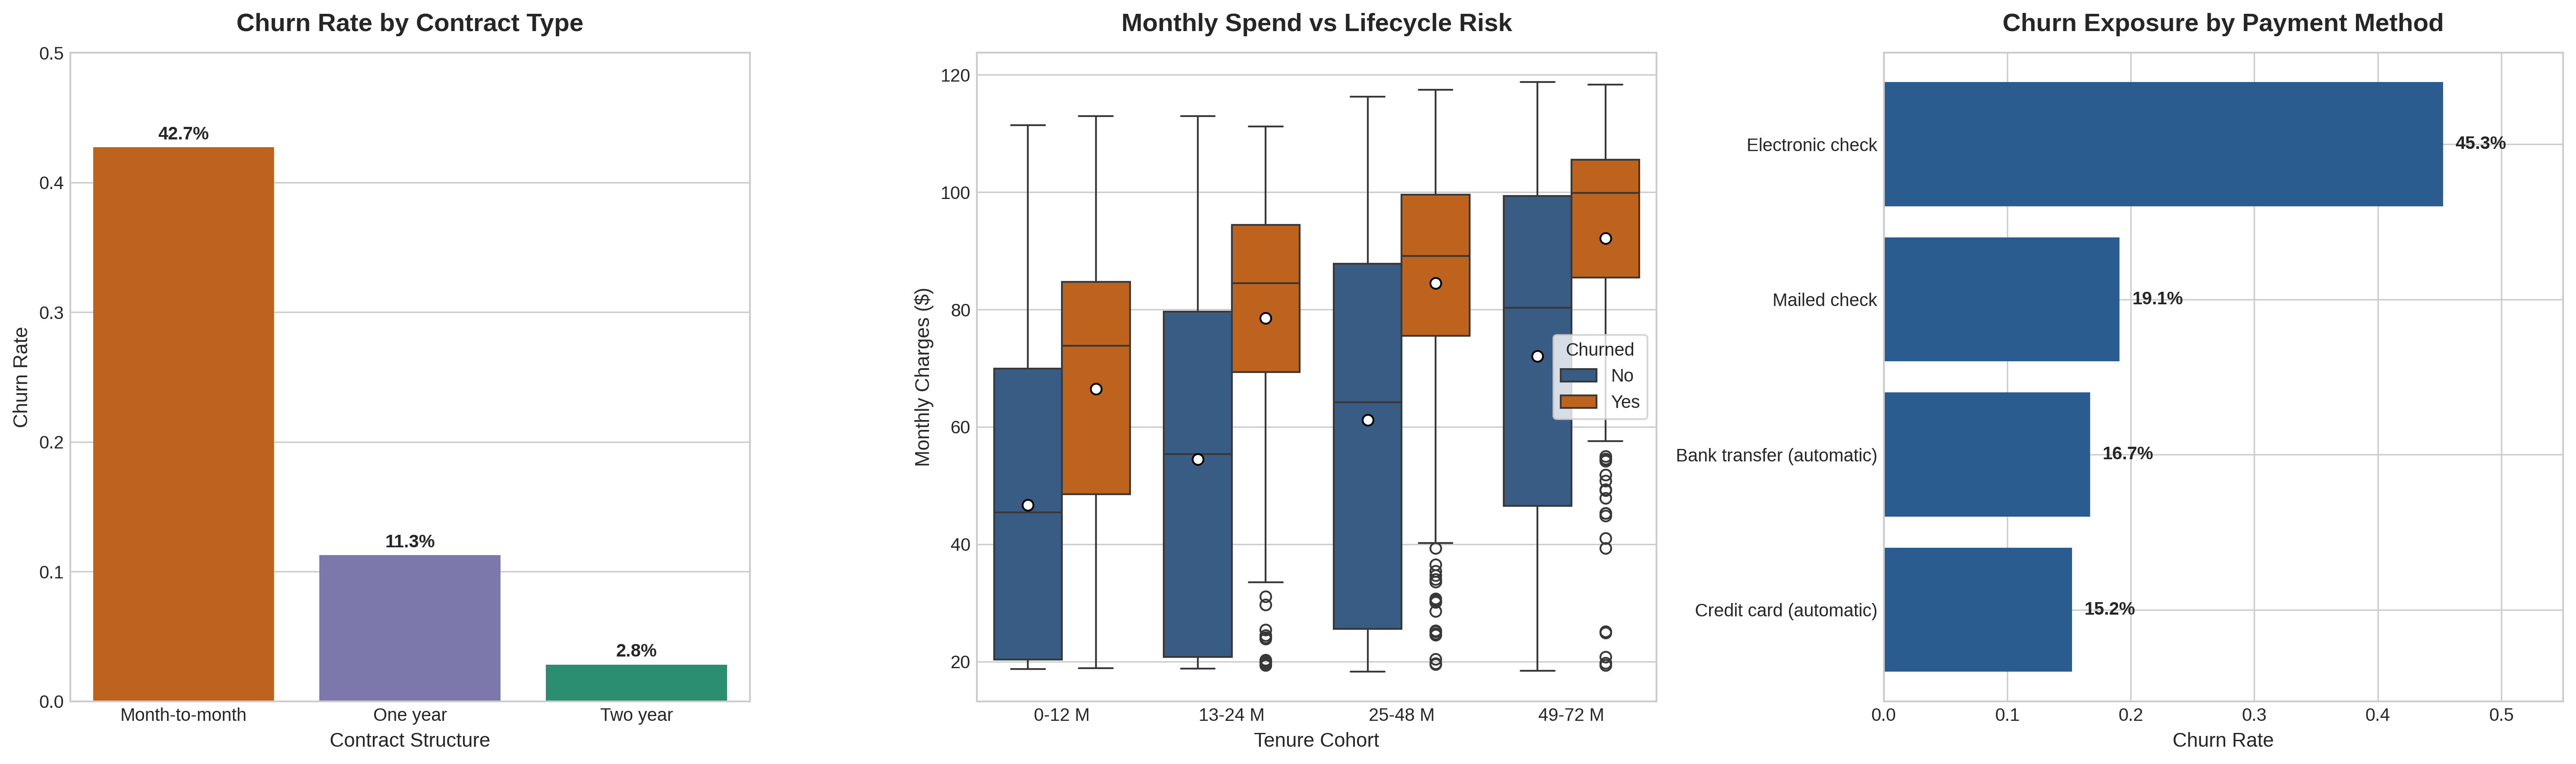

In [8]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6), dpi=300)

palette = {"No": "#2b5c8f", "Yes": "#d95f02"}

# Panel 1: Contract Analysis
contract_summary = (
    df.groupby("contract")["churn_numeric"]
    .mean()
    .reset_index()
    .sort_values(by="churn_numeric", ascending=False)
)
sns.barplot(
    data=contract_summary,
    x="contract",
    y="churn_numeric",
    ax=axes[0],
    palette=["#d95f02", "#7570b3", "#1b9e77"]
)
axes[0].set_title("Churn Rate by Contract Type", fontsize=14, fontweight="bold", pad=12)
axes[0].set_ylabel("Churn Rate", fontsize=11)
axes[0].set_xlabel("Contract Structure", fontsize=11)
axes[0].set_ylim(0, 0.5)
for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.1%}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 7),
        textcoords="offset points",
        fontweight="semibold"
    )

# Panel 2: Tenure vs Spend Risk
sns.boxplot(
    data=df,
    x="tenure_cohort",
    y="monthly_charges",
    hue="churn",
    ax=axes[1],
    palette=palette,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"}
)
axes[1].set_title("Monthly Spend vs Lifecycle Risk", fontsize=14, fontweight="bold", pad=12)
axes[1].set_ylabel("Monthly Charges ($)", fontsize=11)
axes[1].set_xlabel("Tenure Cohort", fontsize=11)
axes[1].legend(title="Churned", frameon=True)

# Panel 3: Payment Method Risk
payment_summary = (
    df.groupby("payment_method")["churn_numeric"]
    .mean()
    .reset_index()
    .sort_values(by="churn_numeric", ascending=True)
)
axes[2].barh(
    payment_summary["payment_method"],
    payment_summary["churn_numeric"],
    color="#2b5c8f"
)
axes[2].set_title("Churn Exposure by Payment Method", fontsize=14, fontweight="bold", pad=12)
axes[2].set_xlabel("Churn Rate", fontsize=11)
axes[2].set_xlim(0, 0.55)
for index, value in enumerate(payment_summary["churn_numeric"]):
    axes[2].text(value + 0.01, index, f"{value:.1%}", va="center", fontweight="semibold")

plt.tight_layout()
plt.savefig("churn_analysis_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

In [9]:
from google.colab import files

files.download("churn_analysis_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>